<a href="https://colab.research.google.com/github/simdongsub/2026.LA/blob/main/ex02_transform_tiefighter_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### 라이브러리 선언

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon

INF = 1000  # 그림판 크기
LEN = 100   # 처음 사각형의 크기

### 축 그리기 및 사각형 그리기

In [ ]:
def draw_axis(ax):
  ax.axhline(0, color='black', alpha=0.3)  # x-axis line
  ax.axvline(0, color='black', alpha=0.3)  # y-axis line
  ax.set_xlim(-INF, INF)
  ax.set_ylim(-INF, INF)
  ax.set_aspect('equal')  # 정사각형 모양으로 backboard 그리기

In [ ]:
def draw_rectangle(ax, p1, p2, p3, p4):
  my_polygon = Polygon([p1, p2, p3, p4])
  ax.add_patch(my_polygon)

In [ ]:
def draw_object(ax):
  p1 = np.array([0, 0])
  p2 = np.array([LEN, 0])
  p3 = np.array([LEN, LEN])
  p4 = np.array([0, LEN])

  draw_rectangle(ax, p1, p2, p3, p4)

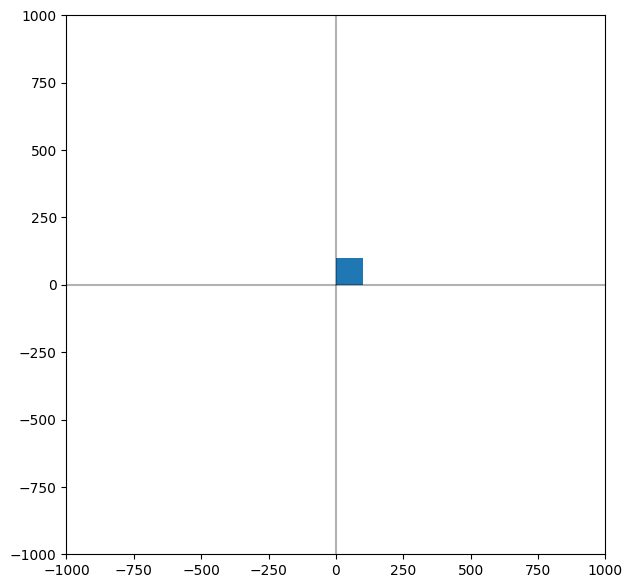

In [ ]:
# 그림판 선언 및 크기 설정
fig, ax = plt.subplots(figsize=(7,7))

# 축 그리기
draw_axis(ax)

# 물체 그리기
draw_object(ax)

plt.show()

### 본론
#### 1. 변환 구현
* translate(p, dx, dy)
* rotate(p, theta)  
* scale(p, sx, sy)  
* shear_x(p, sx)  
* shear_y(p, sy)  
* reflect_x(p)  
* reflect_y(p)   
* ...

In [ ]:
# 점 p를 x축 방향으로 dx만큼, y축 방향으로 dy만큼 이동시킨 점 q를 구할 것
# q = T(dx, dy) p1
def translate(p, dx, dy):
  # 1. 동차좌표계 (homogeneous coordinate)으로 변환
  hp = np.array([p[0], p[1], 1.0])

  # 2. 이동 변환 행렬 생성
  m = np.array([[1.0, 0.0, dx], [0.0, 1.0, dy], [0.0, 0.0, 1.0]])

  # 3. 행렬과 벡터의 곱
  q = np.dot(m, hp)  # (3,3) x (3,1) -> (3,1)
  #print(q)

  # 4. 2차원 좌표계로 변환
  q = np.array([q[0], q[1]])
  return q

In [ ]:
def scale(p, sx, sy):
    hp = np.array([p[0], p[1], 1.0])

    m = np.array([
        [sx, 0, 0],
        [0, sy, 0],
        [0, 0, 1]
    ])

    q = np.dot(m, hp)
    return np.array([q[0], q[1]])


def rotate(p, theta):
    hp = np.array([p[0], p[1], 1.0])

    m = np.array([
        [np.cos(theta), -np.sin(theta), 0],
        [np.sin(theta), np.cos(theta), 0],
        [0, 0, 1]
    ])

    q = np.dot(m, hp)
    return np.array([q[0], q[1]])

In [ ]:
# x축 방향 기울기 변환
def shear_x(p, sx):
    hp = np.array([p[0], p[1], 1.0])

    m = np.array([
        [1.0, sx, 0.0],
        [0.0, 1.0, 0.0],
        [0.0, 0.0, 1.0]
    ])

    q = np.dot(m, hp)
    return np.array([q[0], q[1]])


# y축 방향 기울기 변환
def shear_y(p, sy):
    hp = np.array([p[0], p[1], 1.0])

    m = np.array([
        [1.0, 0.0, 0.0],
        [sy, 1.0, 0.0],
        [0.0, 0.0, 1.0]
    ])

    q = np.dot(m, hp)
    return np.array([q[0], q[1]])

In [ ]:
# x축 반전
def reflect_x(p):
    hp = np.array([p[0], p[1], 1.0])

    m = np.array([
        [1.0, 0.0, 0.0],
        [0.0, -1.0, 0.0],
        [0.0, 0.0, 1.0]
    ])

    q = np.dot(m, hp)
    return np.array([q[0], q[1]])


# y축 반전
def reflect_y(p):
    hp = np.array([p[0], p[1], 1.0])

    m = np.array([
        [-1.0, 0.0, 0.0],
        [0.0, 1.0, 0.0],
        [0.0, 0.0, 1.0]
    ])

    q = np.dot(m, hp)
    return np.array([q[0], q[1]])


# 원점 반전
def reflect_origin(p):
    hp = np.array([p[0], p[1], 1.0])

    m = np.array([
        [-1.0, 0.0, 0.0],
        [0.0, -1.0, 0.0],
        [0.0, 0.0, 1.0]
    ])

    q = np.dot(m, hp)
    return np.array([q[0], q[1]])


# 직선 y=x에 대한 반전
def reflect_y_eq_x(p):
    hp = np.array([p[0], p[1], 1.0])

    m = np.array([
        [0.0, 1.0, 0.0],
        [1.0, 0.0, 0.0],
        [0.0, 0.0, 1.0]
    ])

    q = np.dot(m, hp)
    return np.array([q[0], q[1]])

#### 2. 파트 그리기
* draw_cockpit(p1, p2, p3, p4)    # 중앙 조종석
* draw_left_arm(p1, p2, p3, p4)   # 왼쪽 날개축
* draw_left_wing(p1, p2, p3, p4)  # 왼쪽 날개
* draw_right_arm(p1, p2, p3, p4)  # 오른쪽 날개축
* draw_right_wing(p1, p2, p3, p4) # 오른쪽 날개

In [ ]:
def draw_cockpit(ax, p1, p2, p3, p4):  # 중앙 조종석
  # 1. 사각형을 원점으로 이동 변환: T(-LEN/2, -LEN/2)
  # q = T(-LEN/2, -LEN/2)p
  q1 = translate(p1, -LEN/2, -LEN/2)
  q2 = translate(p2, -LEN/2, -LEN/2)
  q3 = translate(p3, -LEN/2, -LEN/2)
  q4 = translate(p4, -LEN/2, -LEN/2)

  # 2. 크기 변환: S(5, 5)
  s = 5
  q1 = scale(q1, s, s)
  q2 = scale(q2, s, s)
  q3 = scale(q3, s, s)
  q4 = scale(q4, s, s)

  # 3. 회전 변환: R(pi/4)
  q1 = rotate(q1, 3.14/4.0)
  q2 = rotate(q2, 3.14/4.0)
  q3 = rotate(q3, 3.14/4.0)
  q4 = rotate(q4, 3.14/4.0)


  # 4. polygon 그리기
  draw_rectangle(ax, q1, q2, q3, q4)

In [ ]:
def draw_left_arm(ax, p1, p2, p3, p4):
    points = [
        np.array([-800, -35]),
        np.array([-200, -55]),
        np.array([-200, 55]),
        np.array([-800, 35])
    ]
    draw_rectangle(ax, *points)

In [ ]:
def draw_right_arm(ax, p1, p2, p3, p4):
    points = [
        np.array([200, -55]),
        np.array([800, -35]),
        np.array([800, 35]),
        np.array([200, 55])
    ]
    draw_rectangle(ax, *points)

In [ ]:
def draw_right_wing(ax, p1, p2, p3, p4):
    points = [
        np.array([750, -400]),
        np.array([850, -600]),
        np.array([850, 600]),
        np.array([750, 400])
    ]
    draw_rectangle(ax, *points)

In [ ]:
# 2. tiefigher 그리기
def draw_object(ax):
    p1 = np.array([0, 0])
    p2 = np.array([LEN, 0])
    p3 = np.array([LEN, LEN])
    p4 = np.array([0, LEN])

    draw_left_arm(ax, p1, p2, p3, p4)
    draw_right_arm(ax, p1, p2, p3, p4)

    draw_left_wing(ax, p1, p2, p3, p4)
    draw_right_wing(ax, p1, p2, p3, p4)

    draw_cockpit(ax, p1, p2, p3, p4)

In [ ]:
def draw_left_wing(ax, p1, p2, p3, p4):
    points = [
        np.array([-850, -600]),
        np.array([-750, -400]),
        np.array([-750, 400]),
        np.array([-850, 600])
    ]
    draw_rectangle(ax, *points)

In [ ]:
def draw_white_gaps(ax):
    gaps = [
        # 왼쪽 흰색 삼각형
        [(-480, 0), (-340, -18), (-340, 18)],

        # 오른쪽 흰색 삼각형
        [(480, 0), (340, -18), (340, 18)]
    ]

    for points in gaps:
        triangle = Polygon(
            points,
            closed=True,
            facecolor='white',
            edgecolor='none',
            zorder=10
        )
        ax.add_patch(triangle)

### 3. main

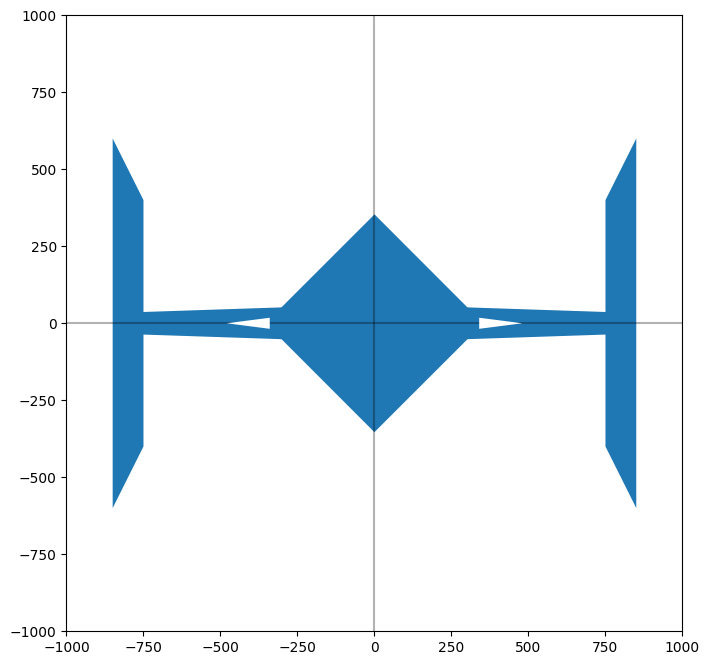

In [ ]:
fig, ax = plt.subplots(figsize=(8, 8))

draw_axis(ax)
draw_object(ax)
draw_white_gaps(ax)

plt.show()